# Pertemuan 4 — Unsupervised Learning
### Praktik: segmentasi pelanggan dengan K-Means

<a href="https://colab.research.google.com/github/[username]/[nama-repo]/blob/main/pertemuan-04/04_Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Ganti `[username]` dan `[nama-repo]` pada tautan di atas (dan path `FILE_DATA` di bagian 2) dengan alamat repositori atau folder Google Drive kelas.

**Setelah menyelesaikan notebook ini, kamu bisa:**

1. Membedakan **supervised** dan **unsupervised learning**.
2. Menjelaskan cara kerja **K-Means** langkah demi langkah.
3. Menjelaskan kenapa **scaling** wajib sebelum clustering.
4. Memilih jumlah segmen (K) dengan **metode elbow**, **silhouette score**, dan pertimbangan bisnis.
5. Membuat **profil segmen** dan memberinya nama yang dimengerti tim marketing.
6. Memvisualisasikan segmen dengan **PCA** dan mengenal metode clustering lain.
7. Menetapkan segmen untuk **pelanggan baru** memakai pipeline.

**Dataset:** `marketing_fitur.csv`, hasil Pertemuan 3 (data bersih + fitur baru, belum di-scaling).

**Perkiraan waktu:** 60–70 menit.

---
## 1. Business case: siapa saja pelanggan kita?

Masih **Juli 2014** di tim marketing *RetailKu* (perusahaan fiktif). Tabel siap model dari Pertemuan 3 sudah diterima. Sebelum kampanye ke-7 dirancang, manajer marketing mengirim pesan:

> *"Selama ini kita mengirim **satu penawaran yang sama** ke semua pelanggan. Hasilnya: hanya sekitar 15% yang merespons. Saya tidak mau begitu lagi. Tolong kelompokkan pelanggan kita menjadi **beberapa segmen** yang jelas bedanya, beri nama, dan sarankan penawaran yang cocok untuk tiap segmen."*

Masalahnya: **tidak ada kolom "segmen"** di data. Tidak ada yang pernah memberi label "pelanggan ini tipe A". Kita harus menemukan kelompoknya dari pola data itu sendiri.

| | Supervised learning (Pertemuan 5) | Unsupervised learning (hari ini) |
|---|---|---|
| Ada jawaban/label? | Ya, misalnya `Response` | Tidak ada |
| Tujuan | Menebak label untuk data baru | Menemukan pola atau kelompok tersembunyi |
| Contoh | Siapa yang akan merespons kampanye? | Ada berapa tipe pelanggan, dan seperti apa? |
| Cara menilai | Bandingkan tebakan dengan jawaban | Apakah kelompoknya kompak, berbeda, dan **berguna bagi bisnis**? |

| Pertanyaan bisnis | Pertanyaan data / teknik |
|---|---|
| Pelanggan mana yang mirip satu sama lain? | Bagaimana mengukur kemiripan? (jarak + scaling) |
| Bagaimana mengelompokkan ribuan pelanggan? | Algoritma apa yang dipakai? (K-Means) |
| Sebaiknya ada berapa segmen? | Bagaimana memilih K? (elbow, silhouette, bisnis) |
| Seperti apa tiap segmen? | Bagaimana membuat profil dan nama segmen? |
| Pelanggan baru masuk segmen mana? | Bagaimana memakai ulang model? (pipeline) |

---
## 2. Menyiapkan alat dan data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

WARNA = "#2B6F7E"
WARNA_SOROT = "#B4501F"
WARNA_SEGMEN = ["#8A9BA8", "#D9A441", "#2B6F7E", "#B4501F"]   # satu warna per segmen
PETA_WARNA = LinearSegmentedColormap.from_list("teal_oranye", [WARNA, "#F4F4F2", WARNA_SOROT])

In [2]:
# Hubungkan Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Tentukan path tempat Anda menyimpan file hasil Pertemuan 3 di Google Drive
FILE_DATA = '/content/drive/MyDrive/UNIPA 2026/Meet 4/marketing_fitur.csv'

df = pd.read_csv(FILE_DATA)
print("Ukuran:", df.shape)

Mounted at /content/drive
Ukuran: (2026, 37)


In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Tenure_days,Children,TotalSpend,TotalPurchases,TotalAcceptedPrev,AvgSpendPerPurchase,AgeGroup,TotalSpend_log,Education_ord
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1,57,665,0,1617,22,0,73.500000,46-60,7.388946,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0,60,115,2,27,4,0,6.750000,46-60,3.332205,1
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0,49,314,0,776,20,0,38.800000,46-60,6.655440,1
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,0,30,141,1,53,6,0,8.833333,<=30,3.988984,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,0,33,163,1,422,14,0,30.142857,31-45,6.047372,3


Pastikan fitur-fitur dari Pertemuan 3 sudah ada: `Age`, `Children`, `TotalSpend`, `TotalSpend_log`, `TotalPurchases`, `AvgSpendPerPurchase`, `TotalAcceptedPrev`.

In [4]:
fitur_p3 = ["Age", "Tenure_days", "Children", "TotalSpend", "TotalSpend_log",
            "TotalPurchases", "AvgSpendPerPurchase", "TotalAcceptedPrev"]
df[fitur_p3].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Age,2026.0,45.1,11.7,18.0,37.0,44.0,55.0,74.0
Tenure_days,2026.0,354.3,202.5,2.0,180.0,353.5,530.0,701.0
Children,2026.0,1.0,0.7,0.0,0.0,1.0,1.0,3.0
TotalSpend,2026.0,607.5,603.4,5.0,69.0,396.5,1047.8,2525.0
TotalSpend_log,2026.0,5.6,1.5,1.8,4.2,6.0,7.0,7.8
TotalPurchases,2026.0,12.6,7.2,0.0,6.0,12.0,18.0,32.0
AvgSpendPerPurchase,2020.0,37.7,30.3,2.7,13.0,29.9,50.2,187.7
TotalAcceptedPrev,2026.0,0.3,0.7,0.0,0.0,0.0,0.0,4.0


---
## 3. Eksplorasi: bisakah kita "melihat" kelompok?

Ingat pertanyaan di Pertemuan 3: setelah transformasi log, histogram `TotalSpend` punya lebih dari satu puncak. Mari lihat pelanggan dalam dua dimensi sekaligus.

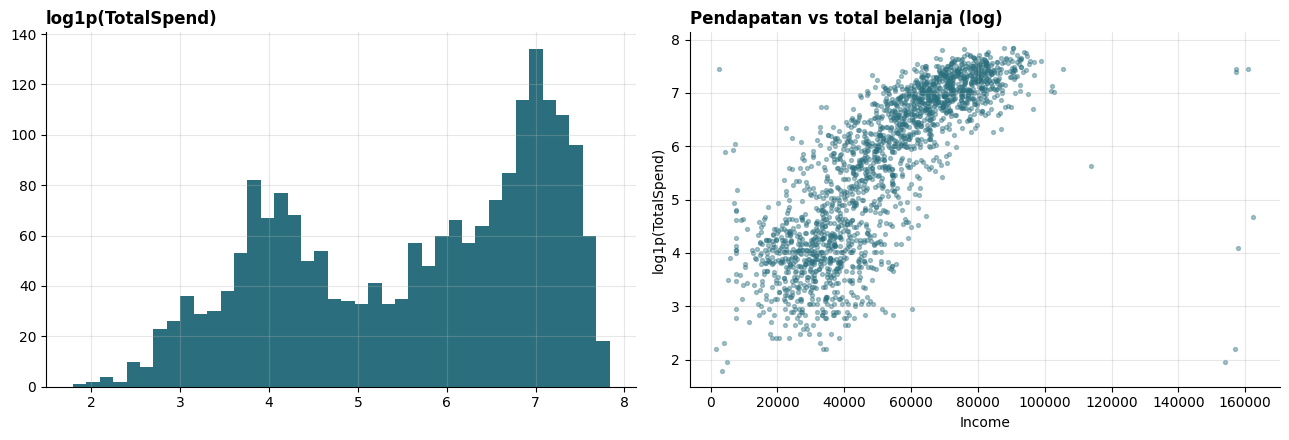

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.hist(df["TotalSpend_log"], bins=40, color=WARNA)
ax1.set_title("log1p(TotalSpend)", loc="left", fontweight="bold")

ax2.scatter(df["Income"], df["TotalSpend_log"], s=8, alpha=0.4, color=WARNA)
ax2.set_title("Pendapatan vs total belanja (log)", loc="left", fontweight="bold")
ax2.set_xlabel("Income")
ax2.set_ylabel("log1p(TotalSpend)")
plt.tight_layout()
plt.show()

💬 **Amati 1:** pada scatter plot, apakah titik-titiknya menyebar rata, atau ada "gumpalan"? Coba tunjuk dengan jari: ada berapa kelompok yang kamu lihat?

💬 **Amati 2:** sekarang bayangkan kita juga memperhitungkan jumlah anak, jumlah pembelian diskon, dan kunjungan web. Itu 6 dimensi. Masih bisakah kita mengelompokkan dengan mata?

Di sinilah algoritma **clustering** membantu: ia mengelompokkan data dalam banyak dimensi sekaligus, dengan satu aturan sederhana: **pelanggan yang mirip masuk kelompok yang sama**.

---
## 4. Mirip = dekat: jarak dan scaling

Di Pertemuan 3 kita sudah menghitung **jarak Euclidean** antar pelanggan. Ingat juga jebakannya: kolom berangka besar mendominasi jarak.

In [6]:
contoh = pd.DataFrame({
    "Income":   [50_000, 51_000, 60_000],
    "Children": [0, 3, 0],
}, index=["A", "B", "C"])

def jarak(data, p, q):
    return np.sqrt(((data.loc[p] - data.loc[q]) ** 2).sum())

rata2, sd = df[["Income", "Children"]].mean(), df[["Income", "Children"]].std()
contoh_skala = (contoh - rata2) / sd

print(f"Tanpa scaling   -> A-B: {jarak(contoh, 'A', 'B'):>8,.1f} | A-C: {jarak(contoh, 'A', 'C'):>8,.1f}")
print(f"Setelah scaling -> A-B: {jarak(contoh_skala, 'A', 'B'):>8.2f} | A-C: {jarak(contoh_skala, 'A', 'C'):>8.2f}")

Tanpa scaling   -> A-B:  1,000.0 | A-C: 10,000.0
Setelah scaling -> A-B:     4.02 | A-C:     0.46


Clustering **sepenuhnya** bergantung pada jarak. Jadi aturan dari Pertemuan 3 berlaku penuh: **semua fitur harus di-scaling dulu**. Di bagian 6 kita akan melihat sendiri apa yang terjadi jika aturan ini dilanggar.

---
## 5. K-Means langkah demi langkah

**K-Means** adalah algoritma clustering paling populer. Kita yang menentukan **K** (jumlah kelompok). Setiap kelompok punya satu titik pusat yang disebut **centroid**.

1. **Mulai:** pilih K titik secara acak sebagai centroid awal.
2. **Kelompokkan:** setiap pelanggan masuk ke centroid **terdekat**.
3. **Perbarui:** pindahkan setiap centroid ke **rata-rata** anggotanya (karena itu namanya K-*Means*).
4. **Ulangi** langkah 2–3 sampai centroid tidak bergerak lagi.

Kita coba secara manual dengan dua fitur saja (`Income` dan `TotalSpend_log`, sudah di-scaling) dan K = 3.

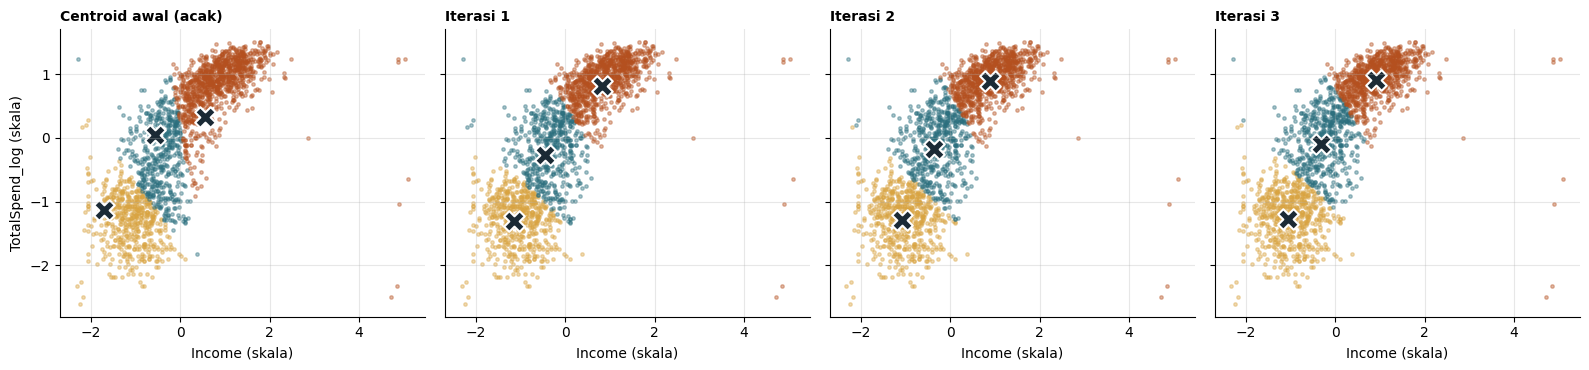

In [7]:
from sklearn.preprocessing import StandardScaler

dua_fitur = StandardScaler().fit_transform(df[["Income", "TotalSpend_log"]])

def langkah_kmeans(X, k=3, n_langkah=4, seed=7):
    rng = np.random.default_rng(seed)
    centroid = X[rng.choice(len(X), size=k, replace=False)]      # langkah 1
    fig, axes = plt.subplots(1, n_langkah, figsize=(4 * n_langkah, 3.8), sharex=True, sharey=True)
    for i, ax in enumerate(axes):
        jarak_ke_c = np.linalg.norm(X[:, None, :] - centroid[None, :, :], axis=2)
        label = jarak_ke_c.argmin(axis=1)                            # langkah 2
        for j in range(k):
            ax.scatter(*X[label == j].T, s=6, alpha=0.4, color=WARNA_SEGMEN[j + 1])
        ax.scatter(*centroid.T, s=220, marker="X", color="#1B2A35", edgecolor="white", linewidth=1.5)
        ax.set_title(f"Iterasi {i}" if i else "Centroid awal (acak)", loc="left", fontweight="bold", fontsize=10)
        centroid = np.array([X[label == j].mean(axis=0) for j in range(k)])   # langkah 3
    axes[0].set_ylabel("TotalSpend_log (skala)")
    for ax in axes:
        ax.set_xlabel("Income (skala)")
    plt.tight_layout()
    plt.show()

langkah_kmeans(dua_fitur)

💬 **Amati:** perhatikan tanda **X** (centroid). Bagaimana posisinya berubah dari panel ke panel? Kapan algoritma berhenti?

💬 **Coba:** ganti `seed=7` menjadi angka lain, misalnya `seed=1`. Apakah hasil akhirnya selalu sama? Apa artinya bagi kita?

<details>
<summary><b>Penjelasan</b></summary>

Hasil K-Means bisa berbeda tergantung centroid awal. Karena itu scikit-learn menjalankan K-Means beberapa kali dengan titik awal berbeda (`n_init`) dan memilih hasil terbaik, yaitu yang total jarak anggota ke centroidnya paling kecil. Kita juga memakai `random_state` agar hasilnya bisa diulang.

</details>

Dalam praktik, kita cukup memakai `KMeans` dari scikit-learn:

In [8]:
from sklearn.cluster import KMeans

km_dua = KMeans(n_clusters=3, n_init=10, random_state=42).fit(dua_fitur)

print("Label 10 pelanggan pertama:", km_dua.labels_[:10])
print("Posisi centroid (skala):\n", km_dua.cluster_centers_.round(2))
print(f"Inertia (total kuadrat jarak ke centroid): {km_dua.inertia_:,.1f}")

Label 10 pelanggan pertama: [0 2 0 2 1 0 1 2 2 2]
Posisi centroid (skala):
 [[ 1.07  0.99]
 [-0.09  0.22]
 [-1.   -1.17]]
Inertia (total kuadrat jarak ke centroid): 806.5


**Inertia** = jumlah kuadrat jarak setiap pelanggan ke centroid kelompoknya. Makin kecil, makin **kompak** kelompoknya. Angka ini kita pakai lagi di bagian 7.

---
## 6. Memilih fitur dan menyiapkan data

### 6.1 Fitur apa yang dipakai untuk segmentasi?

Segmentasi yang baik memakai fitur yang menggambarkan **siapa pelanggan dan bagaimana mereka berbelanja**, dan yang bisa **ditindaklanjuti** oleh tim marketing.

In [9]:
FITUR_SEGMEN = ["Income", "TotalSpend_log", "TotalPurchases", "Children",
                "NumDealsPurchases", "NumWebVisitsMonth"]

df[FITUR_SEGMEN].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Income,2026.0,52027.21,21601.93,1730.00,35422.25,51523.50,68445.75,162397.00
TotalSpend_log,2026.0,5.62,1.47,1.79,4.25,5.99,6.96,7.83
TotalPurchases,2026.0,12.56,7.19,0.00,6.00,12.00,18.00,32.00
Children,2026.0,0.95,0.75,0.00,0.00,1.00,1.00,3.00
NumDealsPurchases,2026.0,2.34,1.93,0.00,1.00,2.00,3.00,15.00
NumWebVisitsMonth,2026.0,5.33,2.44,0.00,3.00,6.00,7.00,20.00


| Fitur | Kenapa dipilih |
|---|---|
| `Income` | Daya beli |
| `TotalSpend_log` | Nilai pelanggan (versi log agar tidak didominasi segelintir pelanggan besar) |
| `TotalPurchases` | Seberapa sering berbelanja |
| `Children` | Tahap hidup / keluarga |
| `NumDealsPurchases` | Kepekaan terhadap diskon |
| `NumWebVisitsMonth` | Keterlibatan di kanal online |

💬 **Diskusi:**

1. Kenapa `ID` jelas tidak dipakai?
2. Kenapa `Response` **sengaja tidak dipakai**? (Petunjuk: kita ingin melihat nanti apakah segmen yang terbentuk *dengan sendirinya* punya tingkat respons berbeda.)
3. Kenapa kolom kategori seperti `Marital_Status` tidak dipakai di sini? Apa arti "jarak" antara Married dan Single setelah one-hot?

### 6.2 Pipeline: isi kosong + scaling

Pada unsupervised learning **tidak ada target**, jadi tidak ada "menebak jawaban" yang perlu diuji. Kita fit pada seluruh data pelanggan. Tetapi prinsip **pipeline** tetap dipakai agar pelanggan baru diproses dengan cara yang persis sama.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

persiapan = Pipeline([
    ("isi_kosong", SimpleImputer(strategy="median")),
    ("skala", StandardScaler()),
])

X = persiapan.fit_transform(df[FITUR_SEGMEN])
print("Ukuran X:", X.shape)
print("Rata-rata tiap kolom:", X.mean(axis=0).round(2))
print("Simpangan baku      :", X.std(axis=0).round(2))

Ukuran X: (2026, 6)
Rata-rata tiap kolom: [ 0. -0. -0.  0.  0. -0.]
Simpangan baku      : [1. 1. 1. 1. 1. 1.]


### 6.3 Eksperimen: apa jadinya tanpa scaling?

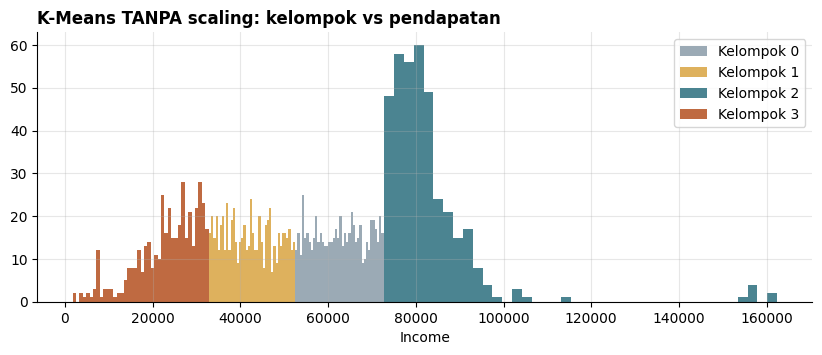

,Income,Children,NumDealsPurchases
kelompok,,,
0,62694.8,0.9,2.8
1,42283.1,1.3,2.7
2,82838.0,0.3,1.3
3,23333.1,1.0,2.1


In [11]:
X_mentah = df[FITUR_SEGMEN].fillna(df[FITUR_SEGMEN].median())
label_mentah = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_mentah)

fig, ax = plt.subplots(figsize=(10, 3.5))
for j in range(4):
    ax.hist(df.loc[label_mentah == j, "Income"], bins=40, color=WARNA_SEGMEN[j], alpha=0.85, label=f"Kelompok {j}")
ax.set_title("K-Means TANPA scaling: kelompok vs pendapatan", loc="left", fontweight="bold")
ax.set_xlabel("Income")
ax.legend()
plt.show()

pd.DataFrame(X_mentah).assign(kelompok=label_mentah).groupby("kelompok")[["Income", "Children", "NumDealsPurchases"]].mean().round(1)

💬 **Amati:** kelompok-kelompok ini terpotong rapi berdasarkan apa? Apakah jumlah anak atau kebiasaan diskon ikut berperan? Apakah ini "segmentasi pelanggan" atau sekadar "kelompok pendapatan"?

---
## 7. Ada berapa segmen? Memilih K

K-Means tidak memberi tahu K terbaik. Kita pakai dua alat bantu, lalu **pertimbangan bisnis**.

- **Metode elbow:** hitung inertia untuk K = 2, 3, …, 10. Inertia selalu turun jika K bertambah; cari titik "siku" saat penurunannya mulai melambat.
- **Silhouette score:** untuk setiap pelanggan, bandingkan seberapa dekat ia dengan kelompoknya sendiri dibanding kelompok tetangga terdekat. Nilainya −1 sampai 1; makin tinggi, makin jelas pemisahannya.

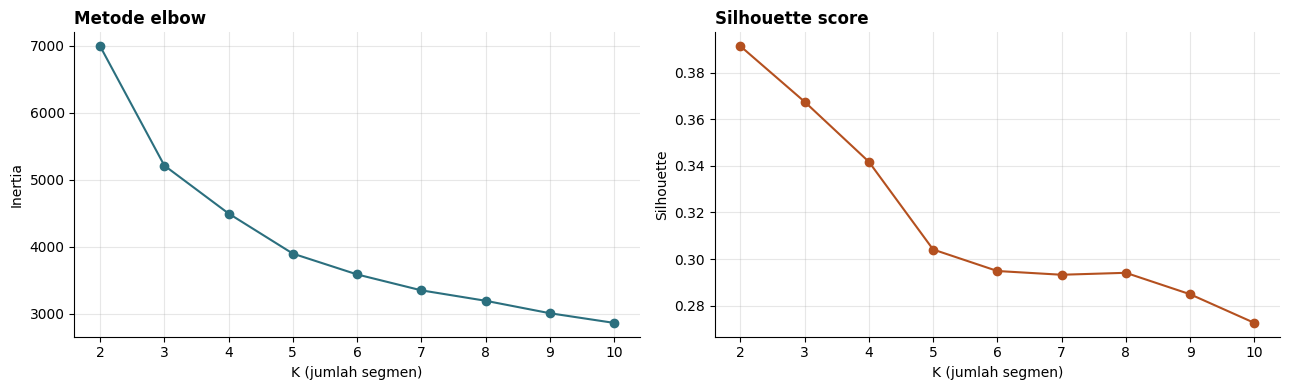

K,2,3,4,5,6,7,8,9,10
inertia,6997.000,5213.000,4496.000,3896.000,3585.000,3347.000,3191.000,3005.000,2861.000
silhouette,0.391,0.367,0.342,0.304,0.295,0.293,0.294,0.285,0.273


In [12]:
from sklearn.metrics import silhouette_score

daftar_k = range(2, 11)
inertia, silhouette = [], []
for k in daftar_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(list(daftar_k), inertia, marker="o", color=WARNA)
ax1.set_title("Metode elbow", loc="left", fontweight="bold")
ax1.set_xlabel("K (jumlah segmen)")
ax1.set_ylabel("Inertia")

ax2.plot(list(daftar_k), silhouette, marker="o", color=WARNA_SOROT)
ax2.set_title("Silhouette score", loc="left", fontweight="bold")
ax2.set_xlabel("K (jumlah segmen)")
ax2.set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

pd.DataFrame({"K": list(daftar_k), "inertia": np.round(inertia), "silhouette": np.round(silhouette, 3)}).set_index("K").T

💬 **Amati:**

1. Di K berapa "siku" grafik elbow?
2. K berapa yang silhouette-nya paling tinggi? Apakah itu otomatis jawaban terbaik?
3. Bayangkan K = 2: "pelanggan besar" dan "pelanggan kecil". Apakah itu cukup untuk merancang kampanye yang berbeda-beda? Bagaimana dengan K = 9: sanggupkah tim marketing membuat 9 kampanye?

<details>
<summary><b>Penjelasan</b></summary>

Silhouette biasanya tertinggi pada K kecil, karena membagi menjadi dua kelompok besar itu mudah. Tetapi dua segmen terlalu kasar untuk marketing. Siku elbow ada di sekitar K = 3–4, dan silhouette masih cukup baik di sana. Kita pilih **K = 4**: cukup rinci untuk penawaran berbeda, masih bisa dikelola tim marketing. Pilihan K selalu gabungan angka **dan** kebutuhan bisnis.

</details>

---
## 8. Membuat segmen final (K = 4)

In [13]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)

# Nomor kelompok dari K-Means bersifat acak. Agar mudah dibaca, kita urutkan
# segmen dari total belanja (median) terendah ke tertinggi: 0 = terendah, 3 = tertinggi.
urutan = df.groupby(kmeans.labels_)["TotalSpend"].median().sort_values().index
PETA_NOMOR = {lama: baru for baru, lama in enumerate(urutan)}

df["Segmen"] = pd.Series(kmeans.labels_).map(PETA_NOMOR).values
print(f"Silhouette K={K}: {silhouette_score(X, df['Segmen']):.3f}")
df["Segmen"].value_counts().sort_index()

Silhouette K=4: 0.342


,count
Segmen,
0,825
1,205
2,536
3,460


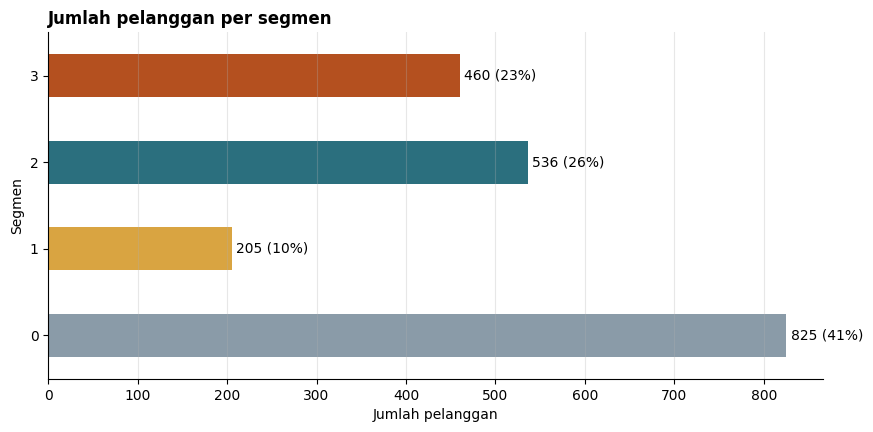

In [14]:
ukuran = df["Segmen"].value_counts().sort_index()

ax = ukuran.plot(kind="barh", color=WARNA_SEGMEN)
ax.set_title("Jumlah pelanggan per segmen", loc="left", fontweight="bold")
ax.set_xlabel("Jumlah pelanggan")
ax.set_ylabel("Segmen")
ax.grid(axis="y", visible=False)
for i, n in enumerate(ukuran):
    ax.text(n + 5, i, f"{n} ({n / len(df) * 100:.0f}%)", va="center")
plt.show()

---
## 9. Profil segmen: memberi makna pada angka

Algoritma hanya memberi **nomor**. Tugas data analyst adalah membaca **seperti apa** setiap segmen dan menerjemahkannya ke bahasa bisnis.

### 9.1 Tabel profil

In [15]:
profil = df.groupby("Segmen").agg(
    jumlah=("ID", "size"),
    pendapatan_median=("Income", "median"),
    belanja_median=("TotalSpend", "median"),
    jml_pembelian=("TotalPurchases", "mean"),
    anak=("Children", "mean"),
    beli_diskon=("NumDealsPurchases", "mean"),
    kunjungan_web=("NumWebVisitsMonth", "mean"),
    umur=("Age", "mean"),
).round(1)
profil

,jumlah,pendapatan_median,belanja_median,jml_pembelian,anak,beli_diskon,kunjungan_web,umur
Segmen,,,,,,,,
0,825,33183.0,57.0,5.3,1.2,1.9,6.5,42.2
1,205,50183.0,467.0,14.7,1.6,6.6,7.2,46.2
2,536,60497.5,765.0,17.5,1.0,2.6,5.3,48.4
3,460,77362.5,1335.0,18.9,0.1,1.0,2.3,46.0


### 9.2 Heatmap: segmen mana yang menonjol di fitur apa?

Angka di tabel punya satuan berbeda-beda, jadi sulit dibandingkan. Kita ubah rata-rata tiap segmen menjadi **z-score**: 0 = sama dengan rata-rata semua pelanggan, positif = di atas rata-rata, negatif = di bawah.

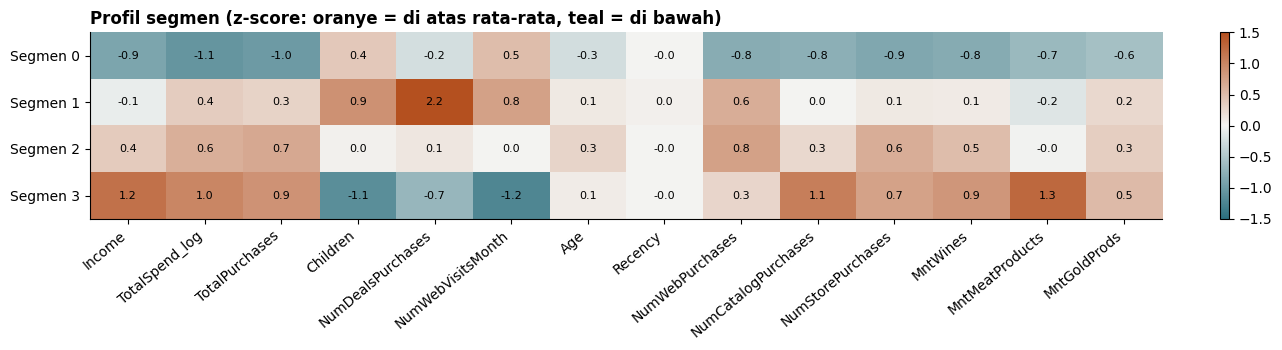

In [16]:
kolom_profil = FITUR_SEGMEN + ["Age", "Recency", "NumWebPurchases", "NumCatalogPurchases",
                               "NumStorePurchases", "MntWines", "MntMeatProducts", "MntGoldProds"]

z = (df.groupby("Segmen")[kolom_profil].mean() - df[kolom_profil].mean()) / df[kolom_profil].std()

fig, ax = plt.subplots(figsize=(13, 3.6))
gambar = ax.imshow(z.values, cmap=PETA_WARNA, vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(kolom_profil)))
ax.set_xticklabels(kolom_profil, rotation=40, ha="right")
ax.set_yticks(range(K))
ax.set_yticklabels([f"Segmen {s}" for s in z.index])
for i in range(K):
    for j in range(len(kolom_profil)):
        ax.text(j, i, f"{z.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.grid(False)
ax.set_title("Profil segmen (z-score: oranye = di atas rata-rata, teal = di bawah)", loc="left", fontweight="bold")
plt.colorbar(gambar, ax=ax, fraction=0.02)
plt.tight_layout()
plt.show()

💬 **Amati:** untuk setiap segmen, sebutkan 2–3 hal yang paling menonjol (kotak paling oranye atau paling teal).

### 9.3 Validasi dengan `Response`

`Response` tidak dipakai untuk membentuk segmen. Justru karena itu, kita bisa memakainya untuk mengecek: apakah segmen yang terbentuk **berguna** untuk kampanye?

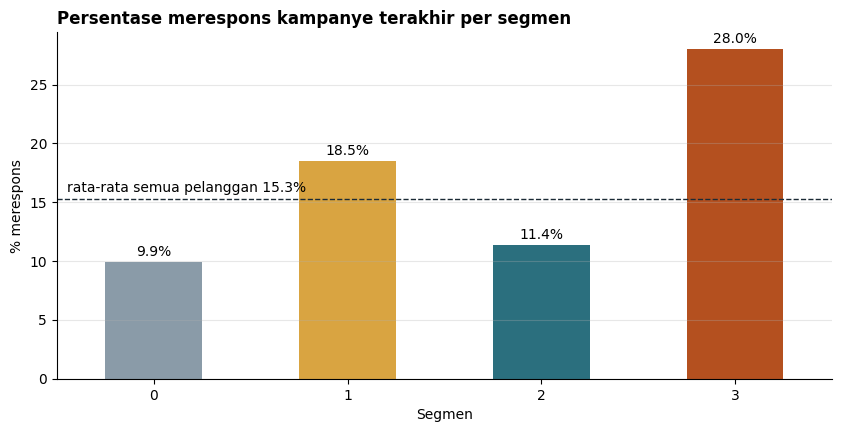

,TotalAcceptedPrev,Complain
Segmen,,
0,0.08,0.01
1,0.22,0.01
2,0.31,0.01
3,0.72,0.01


In [17]:
respons_segmen = df.groupby("Segmen")["Response"].mean() * 100
rata_semua = df["Response"].mean() * 100

ax = respons_segmen.plot(kind="bar", color=WARNA_SEGMEN, rot=0)
ax.axhline(rata_semua, color="#1B2A35", linestyle="--", linewidth=1)
ax.text(-0.45, rata_semua + 0.6, f"rata-rata semua pelanggan {rata_semua:.1f}%", ha="left")
ax.set_title("Persentase merespons kampanye terakhir per segmen", loc="left", fontweight="bold")
ax.set_xlabel("Segmen")
ax.set_ylabel("% merespons")
ax.grid(axis="x", visible=False)
for i, nilai in enumerate(respons_segmen):
    ax.text(i, nilai + 0.5, f"{nilai:.1f}%", ha="center")
plt.show()

df.groupby("Segmen")[["TotalAcceptedPrev", "Complain"]].mean().round(2)

💬 **Diskusi:** segmen mana yang paling responsif? Segmen mana yang paling "mahal" jika dikirimi penawaran yang sama seperti selama ini?

### 9.4 Kanal belanja favorit

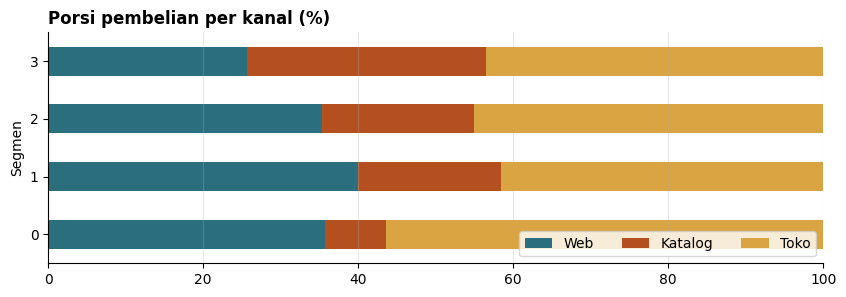

In [18]:
kanal = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
porsi_kanal = df.groupby("Segmen")[kanal].sum()
porsi_kanal = porsi_kanal.div(porsi_kanal.sum(axis=1), axis=0) * 100

ax = porsi_kanal.plot(kind="barh", stacked=True, color=[WARNA, WARNA_SOROT, "#D9A441"], figsize=(10, 3))
ax.set_title("Porsi pembelian per kanal (%)", loc="left", fontweight="bold")
ax.legend(["Web", "Katalog", "Toko"], loc="lower right", ncol=3)
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
plt.show()

### 9.5 Memberi nama segmen

Nama segmen harus **pendek, mudah diingat, dan menggambarkan perilaku**, bukan sekadar "Segmen 2".

| Segmen | Ciri paling menonjol | Nama usulanmu |
|---|---|---|
| 0 | | |
| 1 | | |
| 2 | | |
| 3 | | |

<details>
<summary><b>Bandingkan dengan usulan kami</b> (klik setelah berdiskusi)</summary>

| Segmen | Ciri | Nama |
|---|---|---|
| 0 | Pendapatan dan belanja paling rendah, jarang berbelanja, sering mengunjungi web tapi jarang membeli, punya anak | **Hemat** |
| 1 | Paling banyak membeli dengan diskon, anak paling banyak, kunjungan web tinggi | **Pemburu Diskon** |
| 2 | Pendapatan menengah-atas, belanja cukup besar dan rutin, banyak di toko dan web | **Keluarga Mapan** |
| 3 | Pendapatan dan belanja tertinggi, hampir tanpa anak, jarang pakai diskon, suka katalog, paling responsif | **Premium** |

> Urutan nomor di notebook kamu seharusnya sama karena segmen diurutkan berdasarkan belanja. Jika berbeda, sesuaikan kamus `NAMA_SEGMEN` di bawah.

</details>

In [19]:
NAMA_SEGMEN = {0: "Hemat", 1: "Pemburu Diskon", 2: "Keluarga Mapan", 3: "Premium"}   # sesuaikan jika perlu

df["NamaSegmen"] = df["Segmen"].map(NAMA_SEGMEN)
df.groupby(["Segmen", "NamaSegmen"])[["Income", "TotalSpend", "Children", "NumDealsPurchases", "Response"]].mean().round(2)

,,Income,TotalSpend,Children,NumDealsPurchases,Response
Segmen,NamaSegmen,,,,,
0,Hemat,32845.80,75.34,1.25,1.86,0.10
1,Pemburu Diskon,50457.13,577.12,1.62,6.63,0.19
2,Keluarga Mapan,60040.51,808.60,0.97,2.57,0.11
3,Premium,77791.13,1340.91,0.10,1.00,0.28


---
## 10. Melihat segmen dalam 2 dimensi dengan PCA

Kita memakai 6 fitur, jadi segmen hidup di ruang 6 dimensi. **PCA** (*Principal Component Analysis*) meringkas banyak kolom menjadi beberapa **komponen** baru yang menyimpan sebanyak mungkin variasi data. Dua komponen pertama bisa kita gambar.

> PCA di sini hanya untuk **melihat**. Segmentasi tetap dilakukan pada 6 fitur asli.

Variasi yang tersimpan: [54.9 23.7] % (total 78.6%)


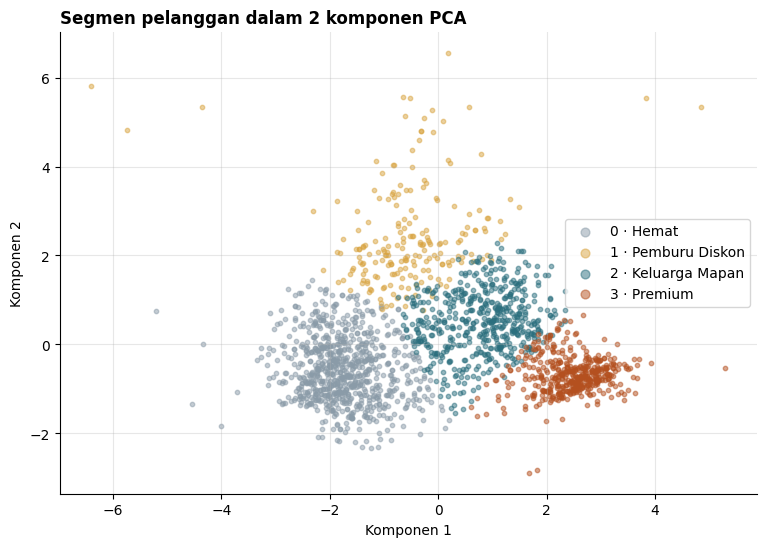

In [20]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)
print("Variasi yang tersimpan:", (pca.explained_variance_ratio_ * 100).round(1), "%",
      f"(total {pca.explained_variance_ratio_.sum() * 100:.1f}%)")

fig, ax = plt.subplots(figsize=(9, 6))
for s in range(K):
    titik = X_2d[df["Segmen"] == s]
    ax.scatter(titik[:, 0], titik[:, 1], s=10, alpha=0.5, color=WARNA_SEGMEN[s], label=f"{s} · {NAMA_SEGMEN[s]}")
ax.set_title("Segmen pelanggan dalam 2 komponen PCA", loc="left", fontweight="bold")
ax.set_xlabel("Komponen 1")
ax.set_ylabel("Komponen 2")
ax.legend(markerscale=2)
plt.show()

In [21]:
# Fitur apa yang membentuk tiap komponen?
pd.DataFrame(pca.components_.T, index=FITUR_SEGMEN, columns=["Komponen 1", "Komponen 2"]).round(2)

,Komponen 1,Komponen 2
Income,0.49,0.08
TotalSpend_log,0.50,0.28
TotalPurchases,0.48,0.30
Children,-0.34,0.40
NumDealsPurchases,-0.10,0.76
NumWebVisitsMonth,-0.40,0.28


💬 **Amati:**

1. Fitur apa yang paling berpengaruh pada Komponen 1? Kalau harus memberi nama, Komponen 1 itu menggambarkan apa?
2. Apakah segmen-segmen terlihat terpisah? Jika ada yang bertumpuk, apakah itu berarti clustering-nya gagal? (Ingat: gambar ini hanya menyimpan sebagian variasi.)

---
## 11. Sekilas metode clustering lain

K-Means bukan satu-satunya cara.

| Metode | Ide | Kelebihan | Kekurangan |
|---|---|---|---|
| **K-Means** | Kelompok di sekitar centroid | Cepat, mudah dijelaskan | Harus menentukan K; cocok untuk kelompok "bulat"; peka outlier |
| **Hierarchical (agglomerative)** | Gabungkan pelanggan termirip sedikit demi sedikit | Tidak perlu K di awal; ada dendrogram | Lambat untuk data besar |
| **DBSCAN** | Kelompok = daerah yang padat | Bentuk kelompok bebas; bisa menandai outlier | Sulit memilih parameter; kurang cocok untuk kepadatan beragam |

### 11.1 Dendrogram (hierarchical clustering)

Kita ambil 40 pelanggan acak agar gambarnya terbaca.

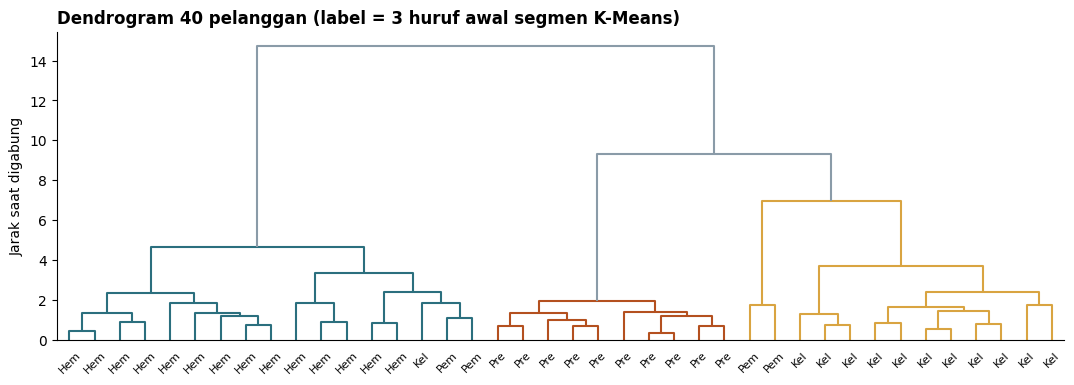

In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram, set_link_color_palette

set_link_color_palette([WARNA, WARNA_SOROT, "#D9A441", "#1B2A35"])

rng = np.random.default_rng(42)
idx = rng.choice(len(X), size=40, replace=False)

fig, ax = plt.subplots(figsize=(13, 4))
dendrogram(linkage(X[idx], method="ward"), ax=ax,
           labels=[NAMA_SEGMEN[s][:3] for s in df["Segmen"].values[idx]],
           color_threshold=7, above_threshold_color="#8A9BA8")
ax.set_title("Dendrogram 40 pelanggan (label = 3 huruf awal segmen K-Means)", loc="left", fontweight="bold")
ax.set_ylabel("Jarak saat digabung")
ax.grid(False)
plt.show()

💬 **Amati:** dendrogram dibaca dari bawah ke atas: pelanggan yang paling mirip digabung lebih dulu. Jika kita "memotong" dendrogram dengan garis mendatar, berapa kelompok yang terbentuk? Apakah pelanggan dengan label segmen yang sama cenderung berkumpul?

---
## 12. Menetapkan segmen untuk pelanggan baru

Pelanggan baru mendaftar setiap hari. Kita tidak perlu mengulang clustering; cukup cari **centroid terdekat**. Satukan persiapan dan model dalam satu pipeline.

In [23]:
model_segmen = Pipeline([
    ("persiapan", persiapan),
    ("kmeans", kmeans),
])

TAHUN_ACUAN = 2014
TANGGAL_ACUAN = pd.Timestamp("2014-07-01")
KOLOM_BELANJA = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
KOLOM_PEMBELIAN = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]

def buat_fitur_ringkas(data):
    """Versi ringkas buat_fitur() dari Pertemuan 3: hanya fitur yang dipakai segmentasi."""
    data = data.copy()
    data["Children"] = data["Kidhome"] + data["Teenhome"]
    data["TotalSpend"] = data[KOLOM_BELANJA].sum(axis=1)
    data["TotalSpend_log"] = np.log1p(data["TotalSpend"])
    data["TotalPurchases"] = data[KOLOM_PEMBELIAN].sum(axis=1)
    return data

pelanggan_baru = pd.DataFrame([
    {"Nama": "Bu Rina", "Income": 82000, "Kidhome": 0, "Teenhome": 0,
     "MntWines": 900, "MntFruits": 60, "MntMeatProducts": 500, "MntFishProducts": 80,
     "MntSweetProducts": 50, "MntGoldProds": 70, "NumWebPurchases": 5,
     "NumCatalogPurchases": 7, "NumStorePurchases": 9, "NumDealsPurchases": 1, "NumWebVisitsMonth": 2},
    {"Nama": "Pak Dodi", "Income": 29000, "Kidhome": 1, "Teenhome": 0,
     "MntWines": 10, "MntFruits": 3, "MntMeatProducts": 12, "MntFishProducts": 4,
     "MntSweetProducts": 2, "MntGoldProds": 8, "NumWebPurchases": 1,
     "NumCatalogPurchases": 0, "NumStorePurchases": 3, "NumDealsPurchases": 2, "NumWebVisitsMonth": 7},
    {"Nama": "Mbak Sari", "Income": np.nan, "Kidhome": 1, "Teenhome": 2,
     "MntWines": 250, "MntFruits": 10, "MntMeatProducts": 90, "MntFishProducts": 15,
     "MntSweetProducts": 10, "MntGoldProds": 40, "NumWebPurchases": 6,
     "NumCatalogPurchases": 2, "NumStorePurchases": 5, "NumDealsPurchases": 8, "NumWebVisitsMonth": 8},
])

fitur_baru = buat_fitur_ringkas(pelanggan_baru)
label_baru = model_segmen.predict(fitur_baru[FITUR_SEGMEN])

pelanggan_baru["Segmen"] = [PETA_NOMOR[l] for l in label_baru]
pelanggan_baru["NamaSegmen"] = pelanggan_baru["Segmen"].map(NAMA_SEGMEN)
pelanggan_baru[["Nama", "Income", "NumDealsPurchases", "Segmen", "NamaSegmen"]]

,Nama,Income,NumDealsPurchases,Segmen,NamaSegmen
0,Bu Rina,82000.0,1,3,Premium
1,Pak Dodi,29000.0,2,0,Hemat
2,Mbak Sari,NaN,8,1,Pemburu Diskon


💬 **Amati:**

1. Apakah segmen tiap pelanggan baru masuk akal menurutmu?
2. Pendapatan Mbak Sari kosong. Dengan nilai apa pipeline mengisinya?
3. Model ini dilatih dengan data sampai Juni 2014. Jika perilaku pelanggan berubah setahun kemudian, apa yang sebaiknya dilakukan?

---
## 13. Menyimpan hasil

Kita simpan data beserta kolom `Segmen` dan `NamaSegmen`. Pertemuan 5 bisa memakai segmen ini sebagai fitur tambahan atau untuk menganalisis hasil prediksi per segmen.

In [24]:
FILE_SEGMEN = "marketing_segmen.csv"
df.to_csv(FILE_SEGMEN, index=False)
print("Tersimpan:", FILE_SEGMEN, "| ukuran:", df.shape)

Tersimpan: marketing_segmen.csv | ukuran: (2026, 39)


In [25]:
# OPSIONAL: unduh file ke komputer (hapus tanda # di dua baris berikut)

# from google.colab import files
# files.download(FILE_SEGMEN)

---
## 14. Latihan mandiri

**Latihan 1 — K lain.** Ulangi bagian 8–9 dengan K = 3 dan K = 5. Segmen mana yang bergabung (K = 3) atau terpecah (K = 5)? Menurutmu, mana yang paling berguna bagi tim marketing?

In [26]:
# Tulis jawaban Latihan 1 di sini

**Latihan 2 — Fitur lain.** Tambahkan `Age` dan `Recency` ke `FITUR_SEGMEN`, lalu hitung ulang silhouette untuk K = 2 sampai 8. Apakah silhouette naik atau turun? Apakah segmen jadi lebih mudah atau lebih sulit diberi nama?
*Petunjuk:* menambah fitur tidak selalu membuat segmen lebih baik.

In [27]:
# Tulis jawaban Latihan 2 di sini

**Latihan 3 — Stabilitas.** Jalankan K-Means (K = 4) dengan `n_init=1` dan lima `random_state` berbeda. Bandingkan hasilnya dengan segmen kita memakai `adjusted_rand_score` (1 = identik, 0 = seperti acak).
*Petunjuk:* `from sklearn.metrics import adjusted_rand_score`

In [28]:
# Tulis jawaban Latihan 3 di sini

**Latihan 4 — Hierarchical vs K-Means.** Pakai `AgglomerativeClustering(n_clusters=4, linkage="ward")` pada `X`, lalu buat `pd.crosstab(df["NamaSegmen"], label_hierarki)`. Seberapa mirip kedua hasil?

In [29]:
# Tulis jawaban Latihan 4 di sini

**Latihan 5 (tantangan) — DBSCAN.** Jalankan `DBSCAN(eps=0.8, min_samples=15)` pada `X`. Berapa kelompok yang terbentuk, dan berapa pelanggan yang ditandai sebagai *noise* (label −1)? Coba ubah `eps`. Kenapa DBSCAN sulit dipakai untuk data ini?

In [30]:
# Tulis jawaban Latihan 5 di sini

---
## 15. Tugas: kartu persona dan rekomendasi kampanye ke-7

Buat **kartu persona** untuk setiap segmen, dalam bahasa yang dimengerti tim marketing.

| Segmen | Nama | Ukuran (%) | Siapa mereka? (2–3 ciri) | % respons kampanye lalu | Penawaran yang cocok | Kanal |
|---|---|---|---|---|---|---|
| 3 | Premium | | Pendapatan dan belanja tertinggi, jarang pakai diskon | | Produk eksklusif, bukan diskon | Katalog |
| | | | | | | |
| | | | | | | |
| | | | | | | |

Lalu tulis **memo 4–6 kalimat** untuk manajer marketing: segmen mana yang diprioritaskan untuk kampanye ke-7, penawaran apa untuk tiap segmen, dan satu keterbatasan dari segmentasi ini.

---
## Rangkuman

| Langkah | Inti | Alat |
|---|---|---|
| Unsupervised learning | Mencari pola tanpa label jawaban | — |
| Mengukur kemiripan | Mirip = dekat; scaling wajib | `StandardScaler` |
| K-Means | Kelompokkan ke centroid terdekat, perbarui centroid, ulangi | `KMeans(n_clusters, n_init, random_state)` |
| Memilih K | Elbow + silhouette + kebutuhan bisnis | `inertia_`, `silhouette_score` |
| Profil segmen | Tabel profil, heatmap z-score, validasi dengan `Response` | `groupby`, `imshow` |
| Visualisasi | Ringkas banyak fitur menjadi 2 dimensi | `PCA` |
| Pelanggan baru | Cari centroid terdekat dalam pipeline | `Pipeline.predict` |

**Pertemuan berikutnya, Classification & Regression:** kali ini **ada** jawabannya. Kita melatih model untuk memprediksi siapa yang akan merespons kampanye (`Response`) dan berapa total belanja pelanggan.